In [ ]:
import random
import pylab as plt
import math
import numpy as np

In [ ]:
def simulate_balls_and_bins(balls,bins):
  bins_dict_to_balls = {i:0 for i in range(1,bins+1)}
  for i in range(balls):
    random_bin = random.randint(1,bins)
    bins_dict_to_balls[random_bin] +=1 
  return bins_dict_to_balls

In [ ]:
def simulate_balls_and_bins_k(balls,bins,k):
  bins_dict_to_balls = {i:0 for i in range(1,bins+1)}
  for i in range(balls):
    min_bin_value = (balls,0)
    possible_bins = list(bins_dict_to_balls.keys())
    for i in range(k):
      random_bin = random.choice(possible_bins)
      del possible_bins[possible_bins.index(random_bin)]
      #print(random_bin)
      if bins_dict_to_balls[random_bin] < min_bin_value[0]:
        min_bin_value = (bins_dict_to_balls[random_bin],random_bin)
    bins_dict_to_balls[min_bin_value[1]] +=1 
  return bins_dict_to_balls

In [ ]:
simulate_balls_and_bins_k(4,4,2)

1
4
4
2
3
2
3
1


{1: 1, 2: 0, 3: 2, 4: 1}

In [ ]:
simulate_balls_and_bins(5,5)

{1: 1, 2: 0, 3: 1, 4: 0, 5: 3}

# Empty Bins Simulation

In [ ]:
def empty_bins_one_trial(balls,bins):
  sim = simulate_balls_and_bins(balls,bins)
  sim_vals = sim.values()
  empty = 0
  for i in sim_vals:
    if i == 0:
      empty += 1
  return empty

In [ ]:
empty_bins_one_trial(5,5)

2

In [ ]:
def empty_bins_trials(balls,bins,trials):
  number_of_empty_bins = 0
  for i in range(trials):
    bins_empty = empty_bins_one_trial(balls,bins)
    number_of_empty_bins += bins_empty
  return number_of_empty_bins/trials

In [ ]:
empty_bins_trials(10000,10000,100)

3672.32

In [ ]:
def expected_empty(n,m):
  return m * (1-(1/m))**n

In [ ]:
def bin_simulation_x_balls_y_expected(balls,bins,trials):
  x_balls = []
  y_expected_value = []
  x_match = []
  y_match = []
  for i in range(0,balls+1,100):
    x_balls.append(i)
    y_expected_value.append(empty_bins_trials(i,bins,trials))
    x_match.append(i)
    y_match.append(expected_empty(i,bins))
  plt.plot(x_balls,y_expected_value,'g')
  plt.title("Simulation of Balls and Bins: Empty Bins")
  plt.xlabel("Number of Balls")
  plt.ylabel("Number of Empty Bins")
  print(x_balls[0],y_expected_value[0],x_balls[-1],y_expected_value[-1])
  print((y_expected_value[0]-y_expected_value[-1])/(x_balls[0]-x_balls[-1]))
  plt.figure()
  plt.plot(x_match,y_match,'r')
  plt.title("Expectation of Balls and Bins: Empty Bins")
  plt.xlabel("Number of Balls")
  plt.ylabel("Expected Number of Empty Bins")

0 100.0 10000 0.0
-0.01


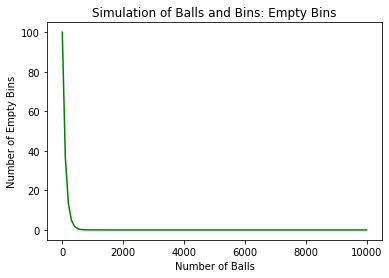

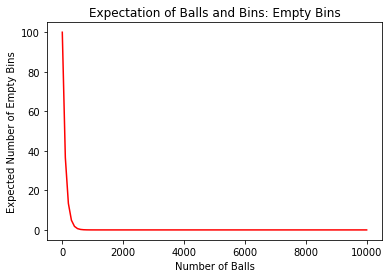

In [ ]:
bin_simulation_x_balls_y_expected(10000,100,3000)

0 1000.0 10000 0.042333333333333334
-0.09999576666666667


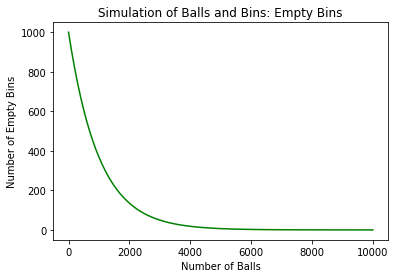

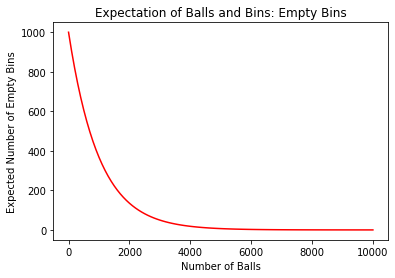

In [ ]:
bin_simulation_x_balls_y_expected(10000,1000,3000)

# Load Histogram of bins

In [ ]:
# Max load, average load, standard deviation of load.
# Later: choose bin using a hash function = int(hashlib.md5(key).hexdigest(),16) % 1000000)/1000000.0
# https://michaelnielsen.org/blog/consistent-hashing/ 
def load_hist_bins(balls,bins_1):
  simulation = simulate_balls_and_bins(balls,bins_1)
  list_of_balls = []
  for i in simulation.keys():
    value = simulation[i]
    for g in range(value):
      list_of_balls.append(i)
  #print(list_of_balls,simulation)
  sim_keys = list(simulation.keys())
  plt.hist(list_of_balls,bins=sim_keys)

In [ ]:
def load_hist_bins_k(balls,bins_1,k):
  simulation = simulate_balls_and_bins_k(balls,bins_1,k)
  list_of_balls = []
  for i in simulation.keys():
    value = simulation[i]
    for g in range(value):
      list_of_balls.append(i)
  #print(list_of_balls,simulation)
  sim_keys = list(simulation.keys())
  plt.hist(list_of_balls,bins=sim_keys)

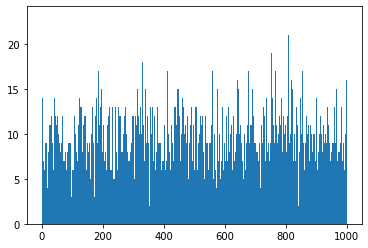

In [ ]:
load_hist_bins(10000,1000)

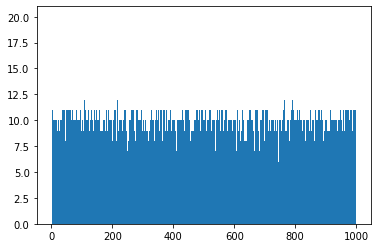

In [ ]:
load_hist_bins_k(10000,1000,2)

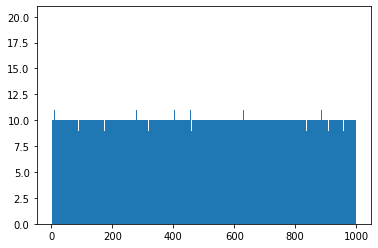

In [ ]:
load_hist_bins_k(10000,1000,50)

In [ ]:
def load_plt_bins(balls,bins_1):
  simulation = simulate_balls_and_bins(balls,bins_1)
  list_of_max_bin = list(simulation.values())
  list_of_max_bin.sort()
  list_of_max_bin.reverse()
  x = [i for i in range(len(list_of_max_bin))]
  plt.plot(x,list_of_max_bin)
  plt.ylim(50,150)
  plt.hlines(balls/bins_1,0,len(list_of_max_bin),colors='r')
  plt.title("Balls in particular bin 1 random choice: Decreasing")
  plt.xlabel("Servers")
  plt.ylabel("Tasks")
  return simulation


def load_plt_bins_k(balls,bins_1,k,plot=False):
  simulation = simulate_balls_and_bins_k(balls,bins_1,k)
  list_of_max_bin = list(simulation.values())
  list_of_max_bin.sort()
  list_of_max_bin.reverse()
  x = [i for i in range(len(list_of_max_bin))]
  if plot == True:
    plt.plot(x,list_of_max_bin)
    plt.ylim(50,150)
    plt.hlines(balls/bins_1,0,len(list_of_max_bin),colors='r')
    plt.title("Balls in particular bin"+" "+ str(k)+" random choices"+": Decreasing")
    plt.xlabel("Servers")
    plt.ylabel("Tasks")
    plt.figure()
    plt.plot(x,list_of_max_bin)
    plt.ylim(95,105)
    plt.hlines(balls/bins_1,0,len(list_of_max_bin),colors='r')
    plt.title("Balls in particular bin"+" "+ str(k)+" random choices"+": Decreasing"+" (Zoomed Up)")
    plt.xlabel("Servers")
    plt.ylabel("Tasks")
  return simulation

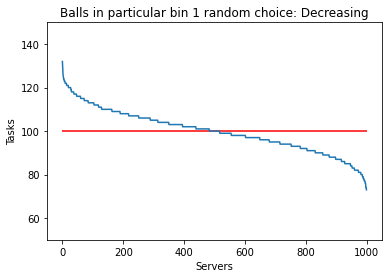

In [ ]:
simulation_dict = load_plt_bins(100000,1000)

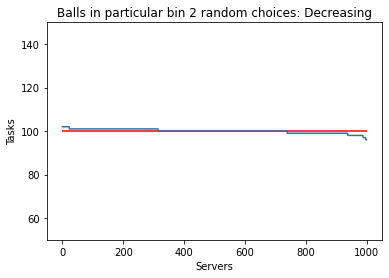

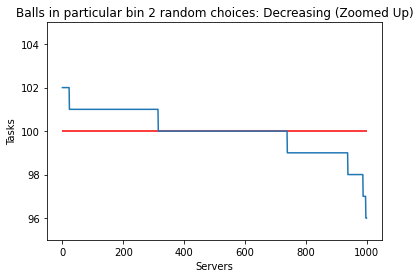

In [ ]:
simulation_dict_2 = load_plt_bins_k(100000,1000,2)

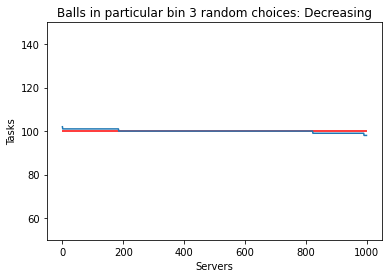

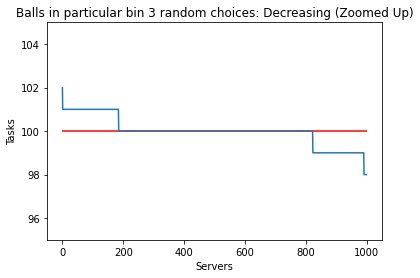

In [ ]:
simulation_dict_3 = load_plt_bins_k(100000,1000,3)

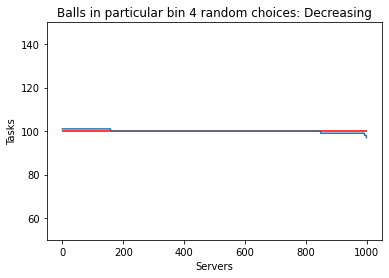

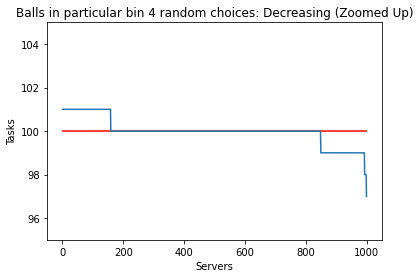

In [ ]:
simulation_dict_4 = load_plt_bins_k(100000,1000,4)

In [ ]:
def statistics_balls_and_bins(simulation_dictionary):
  #Maximum Load
  simulation_vals = list(simulation_dictionary.values())
  simulation_keys = list(simulation_dictionary.keys())
  print("Max Load: ",max(simulation_vals))
  
  
  print("Min Load: ", min(simulation_vals))
  
  print("Bin Range: ", min(simulation_vals),"-", max(simulation_vals))
  
  
  print("Expected Tasks in Server: ", 100)
  
  sums_squared = 0
  expected = sum(simulation_vals)/len(simulation_keys)
  for i in simulation_vals:
    sums_squared += (i-100)**2
  variance = sums_squared / len(simulation_vals)
  print("Variance: ", variance)
  
  print("Standard Deviation: ", round(variance**0.5,4))
  
  bins_below_average = 0
  bins_above_average = 0
  bins_at_average = 0
  for i in simulation_keys:
    if simulation_dictionary[i] > 100:
      bins_above_average += 1
    elif simulation_dictionary[i] == 100:
      bins_at_average += 1
    else:
      bins_below_average += 1
  print("Server Task Count Below Average: ", bins_below_average)
  
  print("Server Task Count at Average: ", bins_at_average)
  
  print("Server Task Count Above Average: ", bins_above_average)
  

In [ ]:
statistics_balls_and_bins(simulation_dict)

Max Load:  132
Servers with Max Load:  1
Min Load:  73
Bin Range:  73 - 132
Servers with Min Load:  1
Expected Tasks in Server:  100.0
Variance:  93.844
Standard Deviation:  9.6873
Server Task Count Below Average:  483
Server Task Count at Average:  34
Server Task Count Above Average:  483


In [ ]:
statistics_balls_and_bins(simulation_dict_2)

Max Load:  102
Servers with Max Load:  23
Min Load:  96
Bin Range:  96 - 102
Servers with Min Load:  3
Expected Tasks in Server:  100.0
Variance:  0.912
Standard Deviation:  0.955
Server Task Count Below Average:  261
Server Task Count at Average:  424
Server Task Count Above Average:  315


In [ ]:
statistics_balls_and_bins(simulation_dict_3)

Max Load:  102
Servers with Max Load:  1
Min Load:  98
Bin Range:  98 - 102
Servers with Min Load:  9
Expected Tasks in Server:  100.0
Variance:  0.392
Standard Deviation:  0.6261
Server Task Count Below Average:  177
Server Task Count at Average:  638
Server Task Count Above Average:  185


In [ ]:
statistics_balls_and_bins(simulation_dict_4)

Max Load:  101
Servers with Max Load:  159
Min Load:  97
Bin Range:  97 - 101
Servers with Min Load:  1
Expected Tasks in Server:  100.0
Variance:  0.336
Standard Deviation:  0.5797
Server Task Count Below Average:  151
Server Task Count at Average:  690
Server Task Count Above Average:  159


#Several Trials Random Choice Simulation

In [ ]:
def n_trials_K_random_choices(balls,bins,k,trials):
  x = [i for i in range(bins)]
  y = {i:0 for i in range(bins)}
  for i in range(trials):
    simulation = load_plt_bins_k(balls,bins,k)
    values = list(simulation.values())
    values.sort()
    values.reverse()
    for i in range(len(values)):
      y[i] += values[i]
  y_vals = list(y.values())
  final_y = []
  for i in y_vals:
    final_y.append(i//trials)
  plt.plot(x,final_y,label=str(k)+" "+"choices")
  plt.title("Simulation of "+str(k)+" choices")
  plt.xlabel("Servers")
  plt.ylabel("Load")
  plt.hlines(balls/bins,0,1000,'r',label="Expectation")
  plt.legend()
  dictionary = {i:final_y[i] for i in range(bins)}
  return dictionary

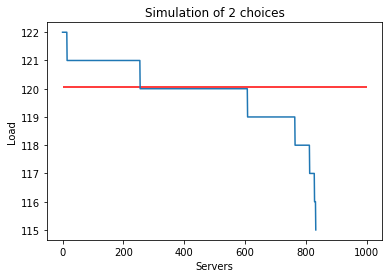

In [ ]:
sim_less = n_trials_K_random_choices(100000,833,2,50)

In [ ]:
statistics_balls_and_bins(sim_less)

Max Load:  122
Min Load:  115
Bin Range:  115 - 122
Expected Tasks in Server:  100
Variance:  398.6086434573829
Standard Deviation:  19.9652
Server Task Count Below Average:  0
Server Task Count at Average:  0
Server Task Count Above Average:  833


In [ ]:
sim = n_trials_K_random_choices(100000,1000,2,50)

In [ ]:
statistics_balls_and_bins(sim)

Max Load:  102
Min Load:  95
Bin Range:  95 - 102
Expected Tasks in Server:  100
Variance:  0.992
Standard Deviation:  0.996
Server Task Count Below Average:  277
Server Task Count at Average:  445
Server Task Count Above Average:  278


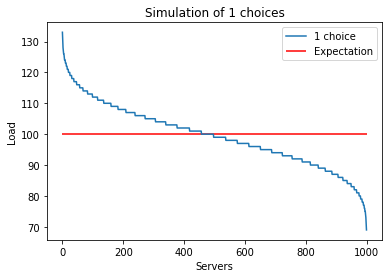

In [ ]:
sim_2 = n_trials_K_random_choices(100000,1000,1,200)

In [ ]:
statistics_balls_and_bins(sim_2)

Max Load:  134
Min Load:  69
Bin Range:  69 - 134
Expected Tasks in Server:  100
Variance:  100.663
Standard Deviation:  10.0331
Server Task Count Below Average:  509
Server Task Count at Average:  40
Server Task Count Above Average:  451


Text(0, 0.5, 'Server Load')

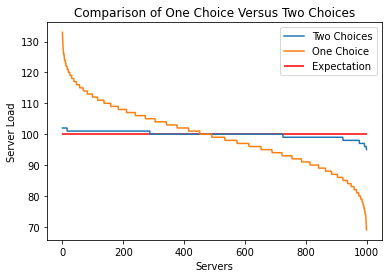

In [ ]:
x = list(sim.keys())
y = list(sim.values())
y_2 = list(sim_2.values())
plt.figure()
plt.plot(x,y,label="Two Choices")
plt.plot(x,y_2,label="One Choice")
plt.hlines(100,0,1000,'r',label="Expectation")
plt.legend()
plt.title("Comparison of One Choice Versus Two Choices")
plt.xlabel("Servers")
plt.ylabel("Server Load")


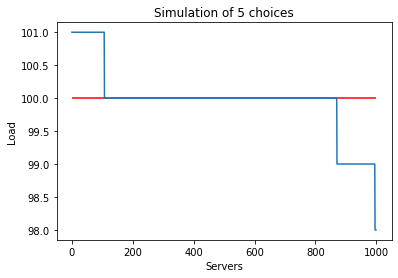

In [ ]:
sim_3 = n_trials_K_random_choices(100000,1000,5,50)

In [ ]:
statistics_balls_and_bins(sim_3)

Max Load:  101
Min Load:  98
Bin Range:  98 - 101
Expected Tasks in Server:  100
Variance:  0.248
Standard Deviation:  0.498
Server Task Count Below Average:  129
Server Task Count at Average:  764
Server Task Count Above Average:  107


#Standard Deviation and Variance as Random Choices Increase

In [ ]:
def variance(dictionary):
  variance = 0
  for i in dictionary.keys():
    variance += (dictionary[i]-100)**2
  return variance / 1000

In [ ]:
def plot_simulation_variance_std(minimum_choices, maximum_choices):
  x = []
  y = []
  y_s = []
  for i in range(minimum_choices, maximum_choices):
    x.append(i)
    dictionary_k = simulate_balls_and_bins_k(100000,1000,i)
    variance_result = variance(dictionary_k)
    y.append(variance_result)
    y_s.append(variance_result**0.5)
  plt.plot(x,y)
  plt.xlabel("Random Choices")
  plt.ylabel("Variance")
  plt.title("Variances as Random Choices Increase")
  plt.figure()
  plt.plot(x,y_s)
  plt.xlabel("Random Choices")
  plt.ylabel("Standard Deviation")
  plt.title("Standard Deviation as Random Choices Increase")

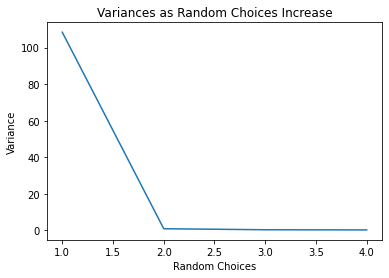

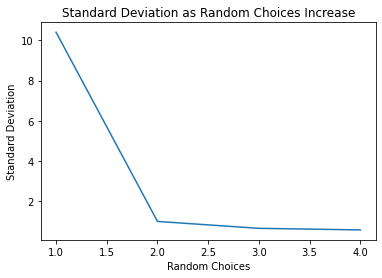

In [ ]:
plot_simulation_variance_std(1,5)

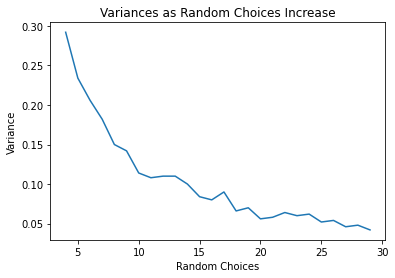

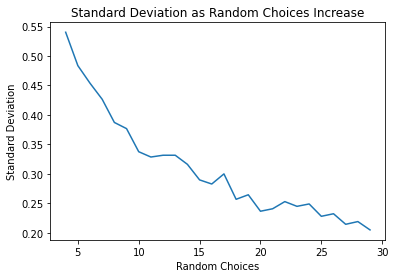

In [ ]:
plot_simulation_variance_std(4,30)

#Loading Balancing Through Request Denying

In [ ]:
def request_deny_load_balancing(tasks,servers):
  index_cur = 0
  try:
    servers_to_tasks_accepting = {i:0 for i in range(servers)}
    servers_to_tasks_full = {}
    indexes_available = [i for i in range(servers)]
    max_load = 100
    for i in range(tasks):
      index_cur = i
      hash_position = random.choice(indexes_available)
      servers_to_tasks_accepting[hash_position] += 1
      if servers_to_tasks_accepting[hash_position] == max_load:
        del indexes_available[indexes_available.index(hash_position)]
        servers_to_tasks_full[hash_position] = max_load
        #print(max(servers_to_tasks_full.values()),servers_to_tasks_full)
  except IndexError:
    new_indexes = [i for i in range(servers)]
    for i in range(index_cur,tasks):
      index_cur = i
      hash_position = random.choice(new_indexes)
      hash_position_2 = random.choice(new_indexes)
      if servers_to_tasks_full[hash_position] < servers_to_tasks_full[hash_position_2]:
        servers_to_tasks_full[hash_position] += 1
      else:
        servers_to_tasks_full[hash_position_2] += 1
  x = list(servers_to_tasks_full.keys())
  y = list(servers_to_tasks_full.values())
  y.sort()
  y.reverse()
  x.sort()
  plt.plot(x,y)
  plt.xlabel("Servers")
  plt.ylabel("Tasks in Server")
  plt.title("Tasks in a Particular Server: Deny Request Method")
  plt.ylim(98,105)
  plt.hlines(100,0,1000,'r')
  return servers_to_tasks_full

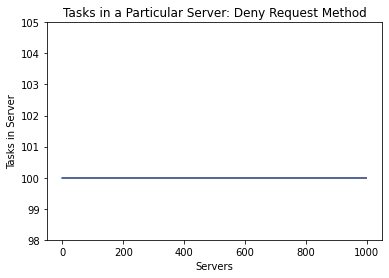

In [ ]:
simulation_deny = request_deny_load_balancing(100000,1000)

In [ ]:
statistics_balls_and_bins(simulation_deny)

Max Load:  100
Servers with Max Load:  1000
Min Load:  100
Bin Range:  100 - 100
Servers with Min Load:  1000
Expected Tasks in Server:  100
Variance:  0.0
Standard Deviation:  0.0
Server Task Count Below Average:  0
Server Task Count at Average:  1000
Server Task Count Above Average:  0


100000


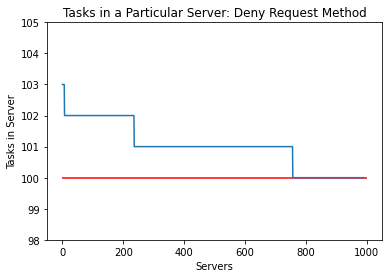

In [ ]:
simulation_deny_2 = request_deny_load_balancing(100000,990)
print(sum(simulation_deny_2.values()))

In [ ]:
statistics_balls_and_bins(simulation_deny_2)

Max Load:  103
Servers with Max Load:  7
Min Load:  100
Bin Range:  100 - 103
Servers with Min Load:  233
Expected Tasks in Server:  100
Variance:  1.5151515151515151
Standard Deviation:  1.2309
Server Task Count Below Average:  0
Server Task Count at Average:  233
Server Task Count Above Average:  757


In [ ]:
def simulation_saving_servers_deny(minimum_servers,maximum_servers):
  x = []
  y = []
  for i in range(minimum_servers,maximum_servers+1):
    dictionary = request_deny_load_balancing(100000,i)
    v = variance(dictionary)
    sd = v**0.5
    y.append(sd)
    x.append(i)
  print(y)
  plt.plot(x,y,'C0')
  plt.xlabel("Servers")
  plt.ylabel("Standard Deviation")
  plt.title("Standard Deviation as Servers Increase")
  plt.xlim(minimum_servers,maximum_servers+1)
  plt.hlines(0.955,0,1000,'r')
  plt.ylim(0,3)

[2.179449471770337, 2.0899760764181012, 1.9763602910400726, 1.8910314645716502, 1.7866169147301836, 1.6935170504013237, 1.6, 1.5112908389850048, 1.4177446878757824, 1.3228756555322954, 1.2288205727444508, 1.1392980294900892, 1.0488088481701516, 0.938083151964686, 0.8567379996241558, 0.752329714952161, 0.6633249580710799, 0.5567764362830022, 0.4538722287164087, 0.31622776601683794, 0.0]


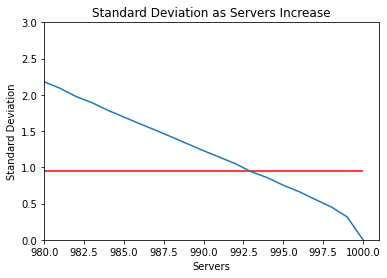

In [ ]:
simulation_saving_servers_deny(980,1000)

# Poisson Distribution


In [ ]:
def poisson_pmf(lambda_1,x):
  return ((lambda_1**x)*(math.e**(-lambda_1)))/(math.gamma(x+1))

In [ ]:
def poission_pmf_simulation(balls,bins):
  simulation = simulate_balls_and_bins(balls,bins)
  bin_number_to_count = {i:0 for i in simulation.values()}
  for i in simulation.keys():
    bin_number_to_count[simulation[i]] += 1
  # Calculate_probability
  x = []
  y = []
  for i in bin_number_to_count:
    x.append(i)
    y.append(bin_number_to_count[i]/bins)
  
  x_pois = []
  y_pois = []
  step = 0.1
  for i in range(0,x[-1]*10):
    y_pois.append(poisson_pmf(balls/bins,step))
    x_pois.append(step)
    step += 0.1
  plt.plot(x_pois,y_pois,'r')
  plt.scatter(x,y)
  #print(x,y)
  #return bin_number_to_count

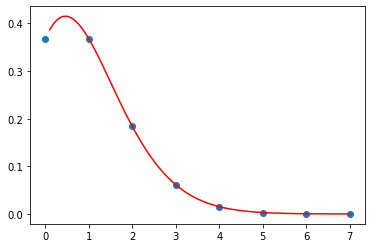

In [ ]:
poission_pmf_simulation(100000,100000)

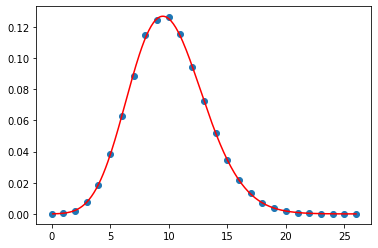

In [ ]:
poission_pmf_simulation(1000000,100000)

In [ ]:
from scipy.optimize import curve_fit
from scipy.stats import norm

In [ ]:
def function(x,loc,scale):
  return norm.pdf(x,loc,scale)

In [ ]:
def poission_pmf_simulation_k(balls,bins,simulation):
  bin_number_to_count = {i:0 for i in simulation.values()}
  for i in simulation.keys():
    bin_number_to_count[simulation[i]] += 1
  # Calculate_probability
  x = []
  y = []
  for i in bin_number_to_count:
    x.append(i)
    y.append(bin_number_to_count[i]/bins)
  plt.scatter(x,y)
  x_1 = []
  y_1 = []
  step = 0.01
  for i in range(x[-1]*100):
    x_1.append(step)
    y_1.append(function(step,balls/bins,0.8859))
    step += 0.01
  plt.plot(x_1,y_1)
  #print(x,y)
  #return bin_number_to_count

In [ ]:
simulation = simulate_balls_and_bins_k(100000,10000,2)

In [ ]:
simulation_2 = simulate_balls_and_bins_k(200000,10000,5)

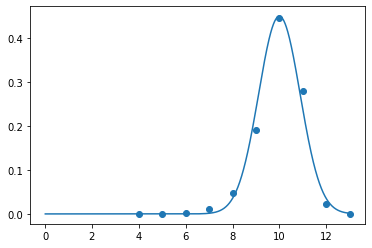

In [ ]:
poission_pmf_simulation_k(100000,10000,simulation)